# NyumbaAI — ML Model Training Notebook
### Web-Based ML-Driven Residential Property Price Prediction System (Nairobi)

| Detail | Value |
|---|---|
| **Project** | NyumbaAI |
| **Student** | Irene Wanjiru Kariuki |
| **Student ID** | 166918 |
| **Programme** | BBIT Year 4, Semester 2 — Strathmore University |
| **Supervisor** | Mr. Jude Mido |
| **Date** | October 2026 |

---

This notebook trains regression models to predict **residential property sale prices** and
**monthly rental prices** in Nairobi. It follows the feature-selection-first pipeline
(correlation filtering → VIF → RFECV) taught in class, adapted for a dual-target prediction task.

**Targets**
- `salePrice` — KES (purchase price)
- `rentalPrice` — KES / month

**Dataset**  `nyumbaai_dataset.csv` — 2,700 rows, 25 Nairobi neighbourhoods,
calibrated against KNBS 2023/24 Kenya Housing Survey and Kaggle Property24 listings.


In [1]:
%pip install ipykernel -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
print(sys.executable)


c:\xampp\htdocs\nyumba_ai\venv\Scripts\python.exe


In [3]:
print(f"Python {sys.version}")


Python 3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]


In [4]:
import subprocess

def silent_pip_install(package: str) -> None:
    """Install a pip package suppressing all output except errors."""
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", package, "-q"],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        print(f"[pip ERROR] {package}:\n{result.stderr}")


In [5]:
silent_pip_install("xgboost")
silent_pip_install("scikit-learn")
silent_pip_install("pandas")
silent_pip_install("numpy")
silent_pip_install("matplotlib")
silent_pip_install("seaborn")
silent_pip_install("joblib")
silent_pip_install("statsmodels")
silent_pip_install("python-dotenv")

print("All packages installed.")


All packages installed.


In [6]:
import os

def resolve_environment() -> str:
    """Detect whether we are running in Google Colab or a local DEV environment."""
    try:
        import google.colab  # noqa: F401
        return "COLAB"
    except ImportError:
        return "DEV"

ENVIRONMENT = resolve_environment()
print(f"Environment: {ENVIRONMENT}")


Environment: DEV


In [7]:
if ENVIRONMENT == "DEV":
    from dotenv import load_dotenv
    load_dotenv()
    print(".env loaded (DEV mode)")
else:
    print("Colab mode — no .env needed")


.env loaded (DEV mode)


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold, KFold)
from sklearn.preprocessing   import LabelEncoder, StandardScaler
from sklearn.metrics          import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble         import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model     import Ridge
from sklearn.svm              import SVR
from sklearn.feature_selection import RFECV
from xgboost import XGBRegressor
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import joblib

sns.set_style("whitegrid")
RANDOM_STATE = 42

print("All imports successful.")


All imports successful.


## 1. Load Dataset

In [9]:
if ENVIRONMENT == "COLAB":
    from google.colab import files
    print("Upload nyumbaai_dataset.csv when prompted...")
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
else:
    # DEV: the dataset lives in the project's data/ folder
    DATA_PATH = "../data/nyumbaai_dataset.csv"

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head()


Loaded: 2,700 rows × 13 columns


,propertyType,location,geoScore,bedrooms,bathrooms,sizeSqm,hasParking,hasDSQ,hasGarden,hasBorehole,isFurnished,salePrice,rentalPrice
0,Maisonette,Kileleshwa,0.88,3,4,NaN,True,False,False,False,False,18000000,90500
1,Bungalow,Ngong Road,0.78,4,4,NaN,True,False,False,False,False,9050000,54500
2,Apartment,Upper Hill,0.83,2,3,77.6,False,False,False,True,False,11800000,55000
3,Bungalow,Karen,0.96,3,2,121.7,False,True,False,True,True,95450000,472500
4,Villa,Muthaiga,0.95,6,7,141.0,True,True,True,False,False,162500000,513000


In [10]:
TARGETS = ["salePrice", "rentalPrice"]

print("Dataset columns:")
print(df_raw.dtypes.to_string())
print(f"\nTargets: {TARGETS}")


Dataset columns:
propertyType     object
location         object
geoScore        float64
bedrooms          int64
bathrooms         int64
sizeSqm         float64
hasParking       object
hasDSQ             bool
hasGarden          bool
hasBorehole        bool
isFurnished        bool
salePrice         int64
rentalPrice       int64

Targets: ['salePrice', 'rentalPrice']


## 2. Exploratory Data Analysis (EDA)

In [11]:
print("=== MISSING VALUES ===")
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing,
                            "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0].to_string())
print(f"\nTotal rows with any null: {df_raw.isnull().any(axis=1).sum()}")


=== MISSING VALUES ===
            Missing Count  Missing %
sizeSqm               140       5.19
hasParking             58       2.15

Total rows with any null: 198


In [12]:
from scipy import stats as scipy_stats

def distribution_summary(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    """
    Compute a full distribution summary table (matches reference notebook style).
    Columns: min, Q1, Q2 (median), Q3, max, mean, mode, variance, std,
             skewness, kurtosis, IQR, lower_fence, upper_fence
    """
    rows = []
    for col in cols:
        s = df[col].dropna()
        Q1, Q2, Q3 = s.quantile([0.25, 0.50, 0.75])
        IQR = Q3 - Q1
        rows.append({
            "column":       col,
            "min":          round(s.min(), 2),
            "Q1":           round(Q1, 2),
            "Q2 (median)":  round(Q2, 2),
            "Q3":           round(Q3, 2),
            "max":          round(s.max(), 2),
            "mean":         round(s.mean(), 2),
            "mode":         round(float(s.mode().iloc[0]), 2),
            "variance":     round(s.var(), 2),
            "std":          round(s.std(), 2),
            "skewness":     round(float(scipy_stats.skew(s)), 4),
            "kurtosis":     round(float(scipy_stats.kurtosis(s)), 4),
            "IQR":          round(IQR, 2),
            "lower_fence":  round(Q1 - 1.5 * IQR, 2),
            "upper_fence":  round(Q3 + 1.5 * IQR, 2),
        })
    return pd.DataFrame(rows).set_index("column")

numeric_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
summary_tbl = distribution_summary(df_raw, numeric_cols)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
print("=== DISTRIBUTION SUMMARY TABLE ===")
summary_tbl


=== DISTRIBUTION SUMMARY TABLE ===


,min,Q1,Q2 (median),Q3,max,mean,mode,variance,std,skewness,kurtosis,IQR,lower_fence,upper_fence
column,,,,,,,,,,,,,,
geoScore,0.5,0.70,0.83,0.9,9.700000e-01,0.79,0.85,2.000000e-02,0.13,-0.6318,-0.7990,0.20,0.40,1.20
bedrooms,0.0,2.00,3.00,3.0,6.000000e+00,2.50,3.00,2.150000e+00,1.47,-0.2664,-0.5553,1.00,0.50,4.50
bathrooms,1.0,1.00,3.00,4.0,7.000000e+00,2.74,1.00,1.940000e+00,1.39,0.3943,-0.5799,3.00,-3.50,8.50
sizeSqm,18.0,65.17,92.50,113.8,2.185000e+02,89.32,113.70,1.353200e+03,36.79,-0.0582,-0.3228,48.62,-7.76,186.74
salePrice,800000.0,4000000.00,10150000.00,28100000.0,3.461287e+08,23363577.21,1000000.00,1.164208e+15,34120497.59,2.5815,7.6631,24100000.00,-32150000.00,64250000.00
rentalPrice,4000.0,20500.00,58000.00,136750.0,5.400000e+05,105393.15,175500.00,1.794465e+10,133957.65,2.1055,3.5956,116250.00,-153875.00,311125.00


In [13]:
print("=== OUTLIER COUNTS (IQR 1.5× fences) ===")
for col in TARGETS:
    lower = summary_tbl.loc[col, "lower_fence"]
    upper = summary_tbl.loc[col, "upper_fence"]
    n_out = ((df_raw[col] < lower) | (df_raw[col] > upper)).sum()
    pct   = n_out / len(df_raw) * 100
    print(f"  {col:15s}: {n_out:4d} outliers ({pct:.1f}%)  "
          f"[fences: {lower:>12,.0f} – {upper:>12,.0f}]")


=== OUTLIER COUNTS (IQR 1.5× fences) ===
  salePrice      :  267 outliers (9.9%)  [fences:  -32,150,000 –   64,250,000]
  rentalPrice    :  259 outliers (9.6%)  [fences:     -153,875 –      311,125]


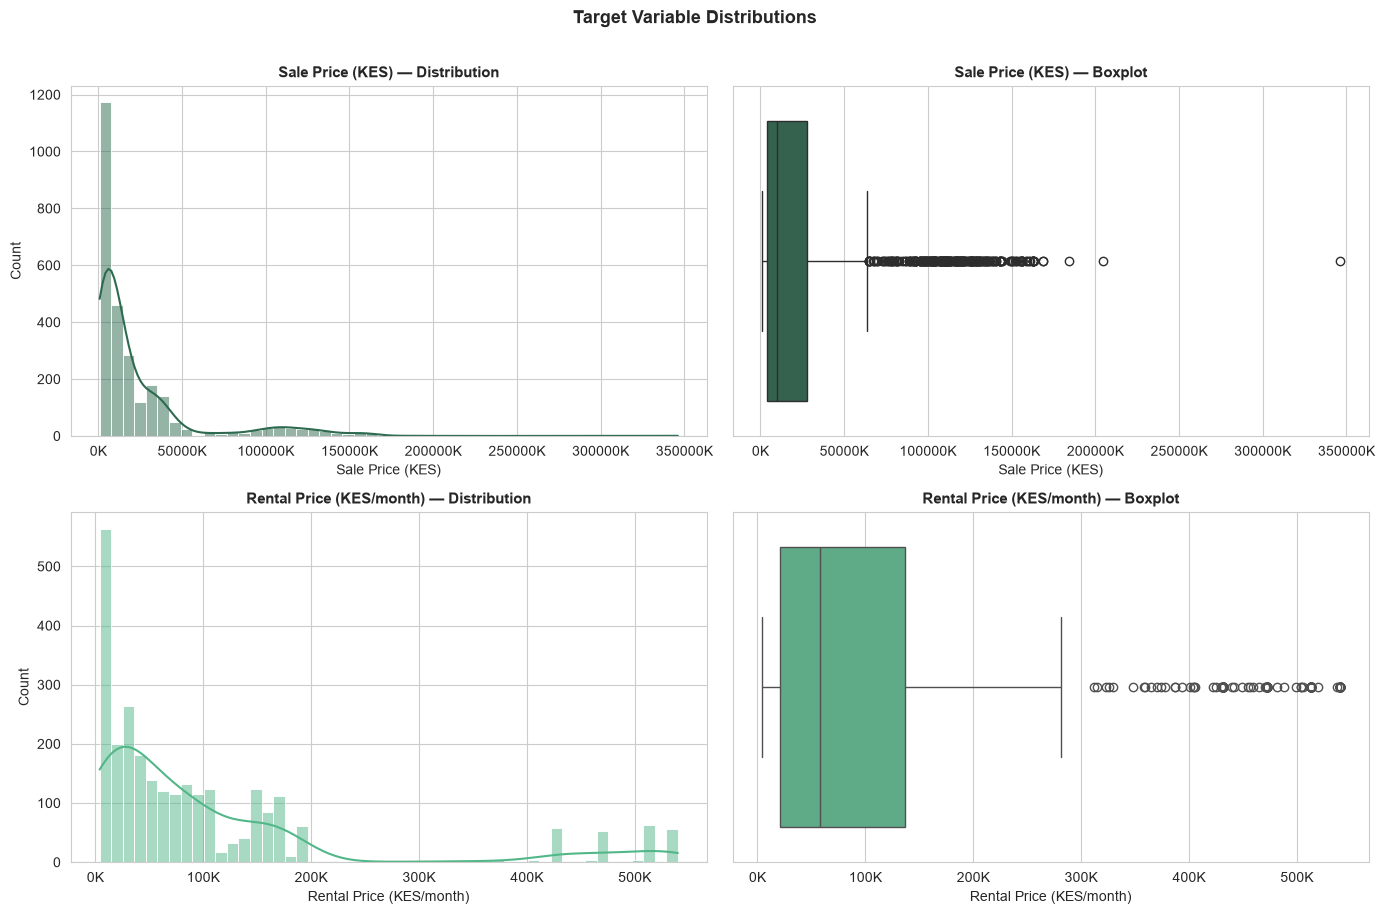

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, (col, label) in enumerate(
    [("salePrice", "Sale Price (KES)"),
     ("rentalPrice", "Rental Price (KES/month)")]
):
    # Histogram
    ax = axes[i][0]
    sns.histplot(df_raw[col].dropna(), bins=50, kde=True,
                 color="#2D6A4F" if i == 0 else "#52B788", ax=ax)
    ax.set_title(f"{label} — Distribution", fontsize=11, fontweight="bold")
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(
        lambda x, _: f"{x/1e6:.1f}M" if col == "salePrice" else f"{x/1e3:.0f}K"))

    # Boxplot
    ax = axes[i][1]
    sns.boxplot(x=df_raw[col].dropna(),
                color="#2D6A4F" if i == 0 else "#52B788", ax=ax)
    ax.set_title(f"{label} — Boxplot", fontsize=11, fontweight="bold")
    ax.set_xlabel(label)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(
        lambda x, _: f"{x/1e6:.1f}M" if col == "salePrice" else f"{x/1e3:.0f}K"))

plt.suptitle("Target Variable Distributions", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


In [15]:
def pearson_spearman_table(df: pd.DataFrame,
                           target: str,
                           features: list) -> pd.DataFrame:
    """
    Compute Pearson and Spearman correlation of each feature vs target.
    Include absolute gap — large gap suggests non-linearity.
    """
    from scipy.stats import pearsonr, spearmanr
    rows = []
    for feat in features:
        col_data = pd.to_numeric(df[feat], errors="coerce")
        tgt_data = pd.to_numeric(df[target], errors="coerce")
        mask = pd.concat([col_data, tgt_data], axis=1).dropna()
        mask.columns = [feat, target]
        p_r, _ = pearsonr(mask[feat], mask[target])
        s_r, _ = spearmanr(mask[feat], mask[target])
        rows.append({
            "feature":  feat,
            "pearson":  round(p_r, 4),
            "spearman": round(s_r, 4),
            "gap":      round(abs(abs(p_r) - abs(s_r)), 4),
        })
    return (pd.DataFrame(rows)
              .set_index("feature")
              .sort_values("spearman", key=abs, ascending=False))

# Run on the CLEAN df (after Section 3 imputation + bool casting)
# If running EDA before cleaning, use df_raw but booleans will be cast via pd.to_numeric above
CANDIDATE_FEATURES = [
    "geoScore", "bedrooms", "bathrooms", "sizeSqm",
    "hasParking", "hasDSQ", "hasGarden", "hasBorehole", "isFurnished"
]

# Use df if available (post-cleaning), else fall back to df_raw
_corr_df = df if "df" in dir() else df_raw

print("=== CORRELATION WITH salePrice ===")
corr_sale = pearson_spearman_table(_corr_df, "salePrice", CANDIDATE_FEATURES)
print(corr_sale.to_string())

print("\n=== CORRELATION WITH rentalPrice ===")
corr_rental = pearson_spearman_table(_corr_df, "rentalPrice", CANDIDATE_FEATURES)
print(corr_rental.to_string())


=== CORRELATION WITH salePrice ===
             pearson  spearman     gap
feature                               
geoScore      0.6158    0.9387  0.3229
bedrooms      0.5121    0.6417  0.1296
sizeSqm       0.4597    0.6004  0.1407
bathrooms     0.4644    0.5380  0.0735
hasDSQ        0.2464    0.2927  0.0463
hasGarden     0.2301    0.2863  0.0562
hasParking    0.1317    0.1494  0.0177
isFurnished   0.0737    0.0946  0.0209
hasBorehole   0.0591    0.0794  0.0204

=== CORRELATION WITH rentalPrice ===
             pearson  spearman     gap
feature                               
geoScore      0.6673    0.9361  0.2687
bedrooms      0.5004    0.6246  0.1242
sizeSqm       0.4523    0.5779  0.1256
bathrooms     0.4399    0.5253  0.0854
hasGarden     0.2326    0.2774  0.0447
hasDSQ        0.2376    0.2772  0.0396
isFurnished   0.1242    0.1723  0.0481
hasParking    0.1399    0.1620  0.0221
hasBorehole   0.0555    0.0765  0.0210


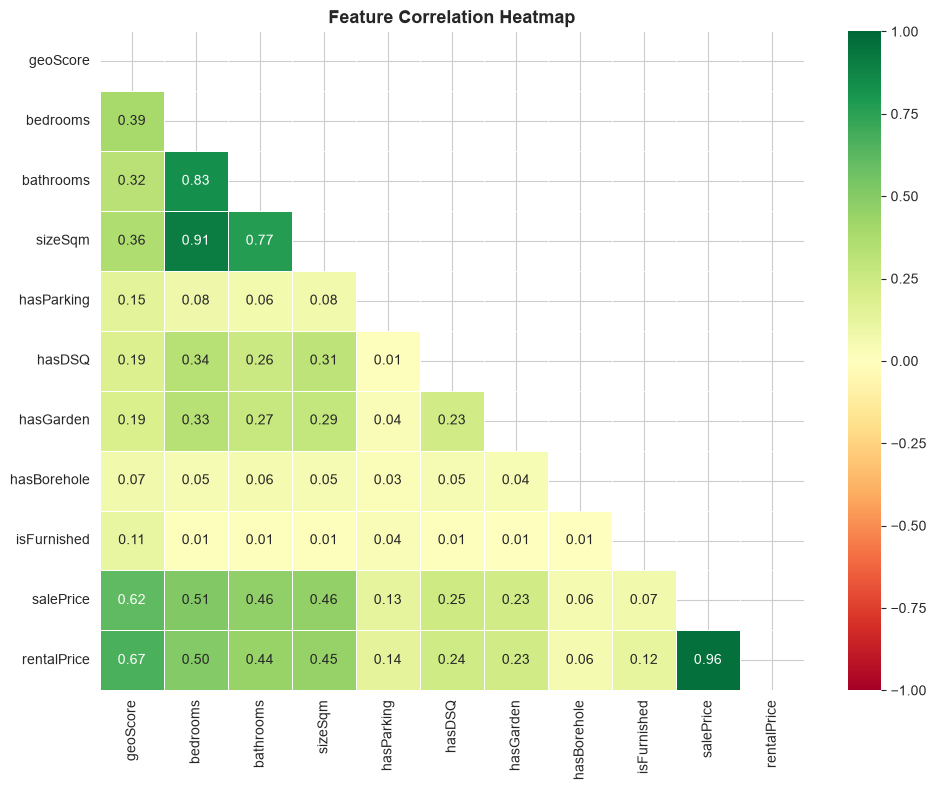

In [16]:
_corr_df = df if "df" in dir() else df_raw

heat_cols = CANDIDATE_FEATURES + ["salePrice", "rentalPrice"]
corr_matrix = _corr_df[heat_cols].apply(pd.to_numeric, errors="coerce").corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
            cmap="RdYlGn", center=0, linewidths=0.5,
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Feature Correlation Heatmap", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


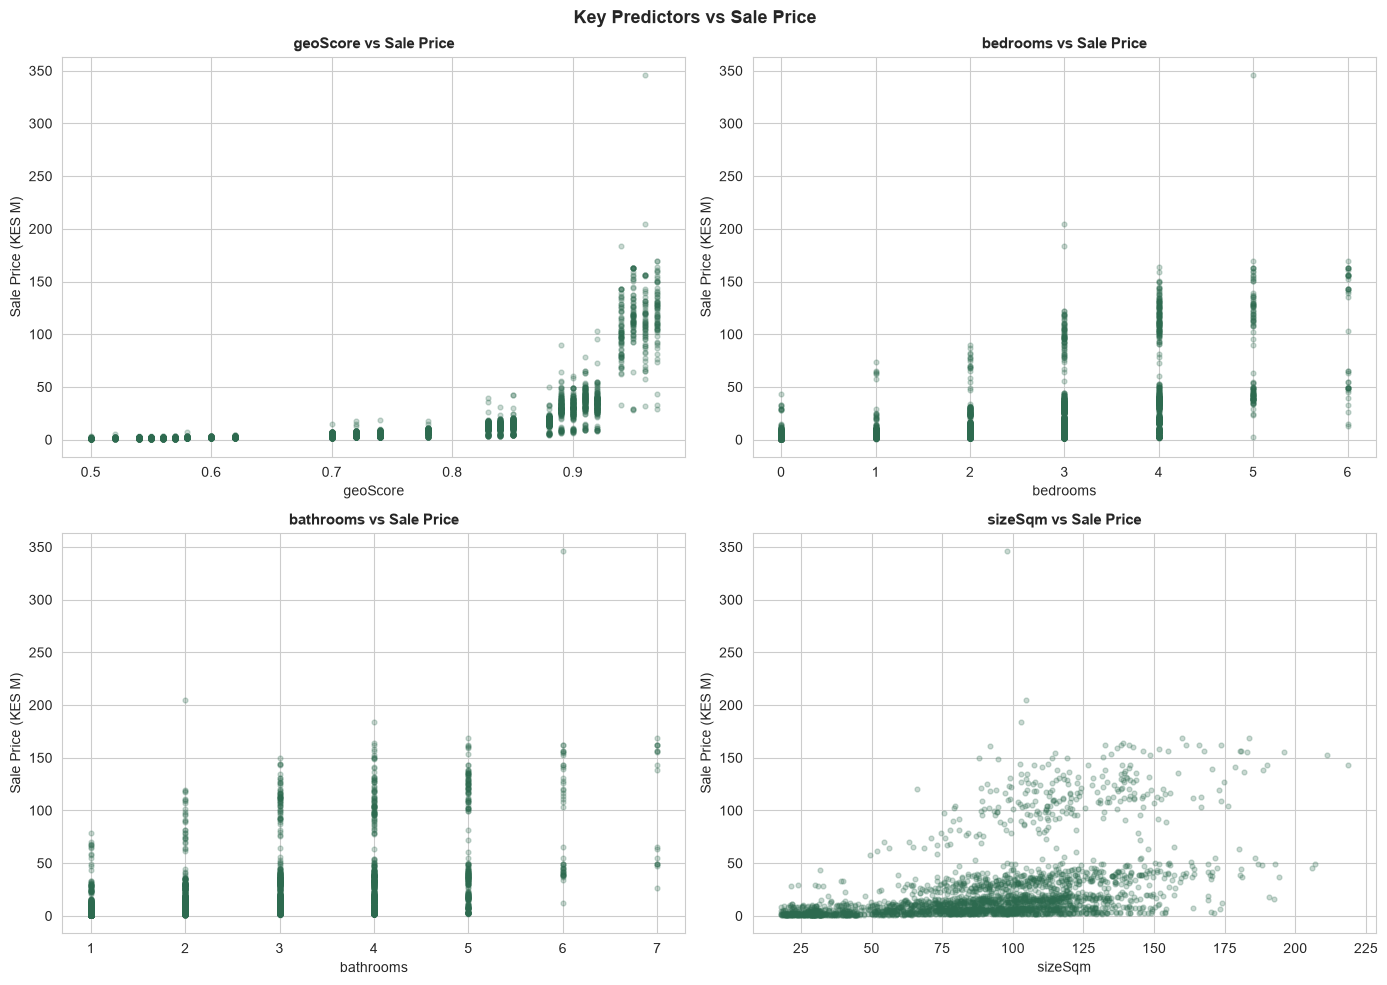

In [17]:
key_preds = ["geoScore", "bedrooms", "bathrooms", "sizeSqm"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(key_preds):
    data = df_raw[[feat, "salePrice"]].dropna()
    axes[i].scatter(data[feat], data["salePrice"] / 1e6,
                    alpha=0.25, s=12, color="#2D6A4F")
    axes[i].set_xlabel(feat, fontsize=10)
    axes[i].set_ylabel("Sale Price (KES M)", fontsize=10)
    axes[i].set_title(f"{feat} vs Sale Price", fontsize=11, fontweight="bold")

plt.suptitle("Key Predictors vs Sale Price", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


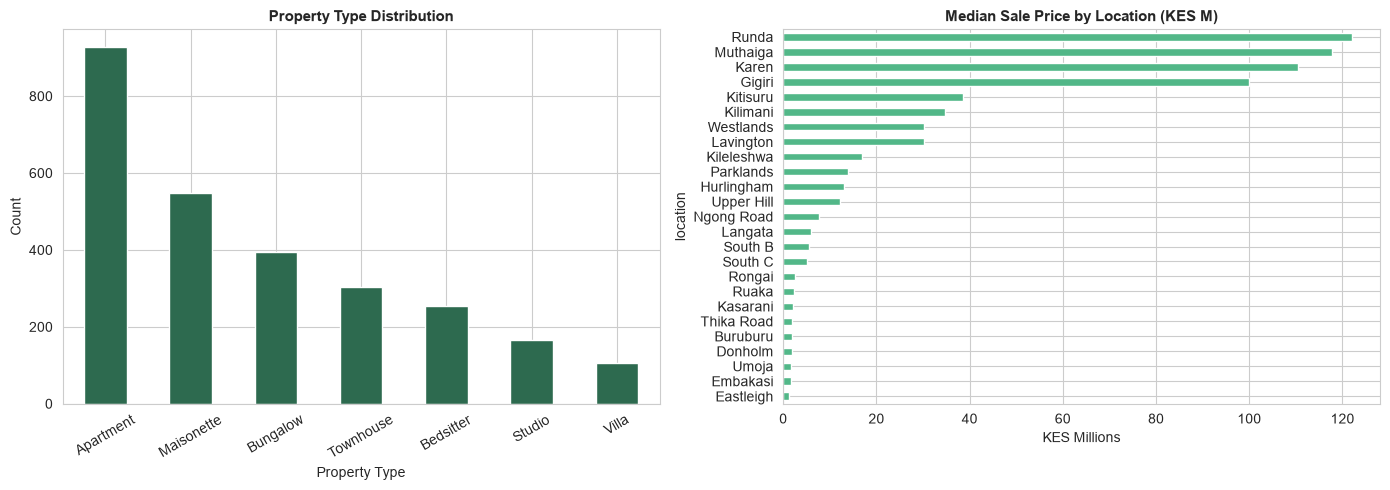

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_raw["propertyType"].value_counts().plot(
    kind="bar", ax=axes[0], color="#2D6A4F", edgecolor="white")
axes[0].set_title("Property Type Distribution", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Property Type")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=30)

df_raw.groupby("location")["salePrice"].median().sort_values().div(1e6).plot(
    kind="barh", ax=axes[1], color="#52B788", edgecolor="white")
axes[1].set_title("Median Sale Price by Location (KES M)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("KES Millions")

plt.tight_layout()
plt.show()


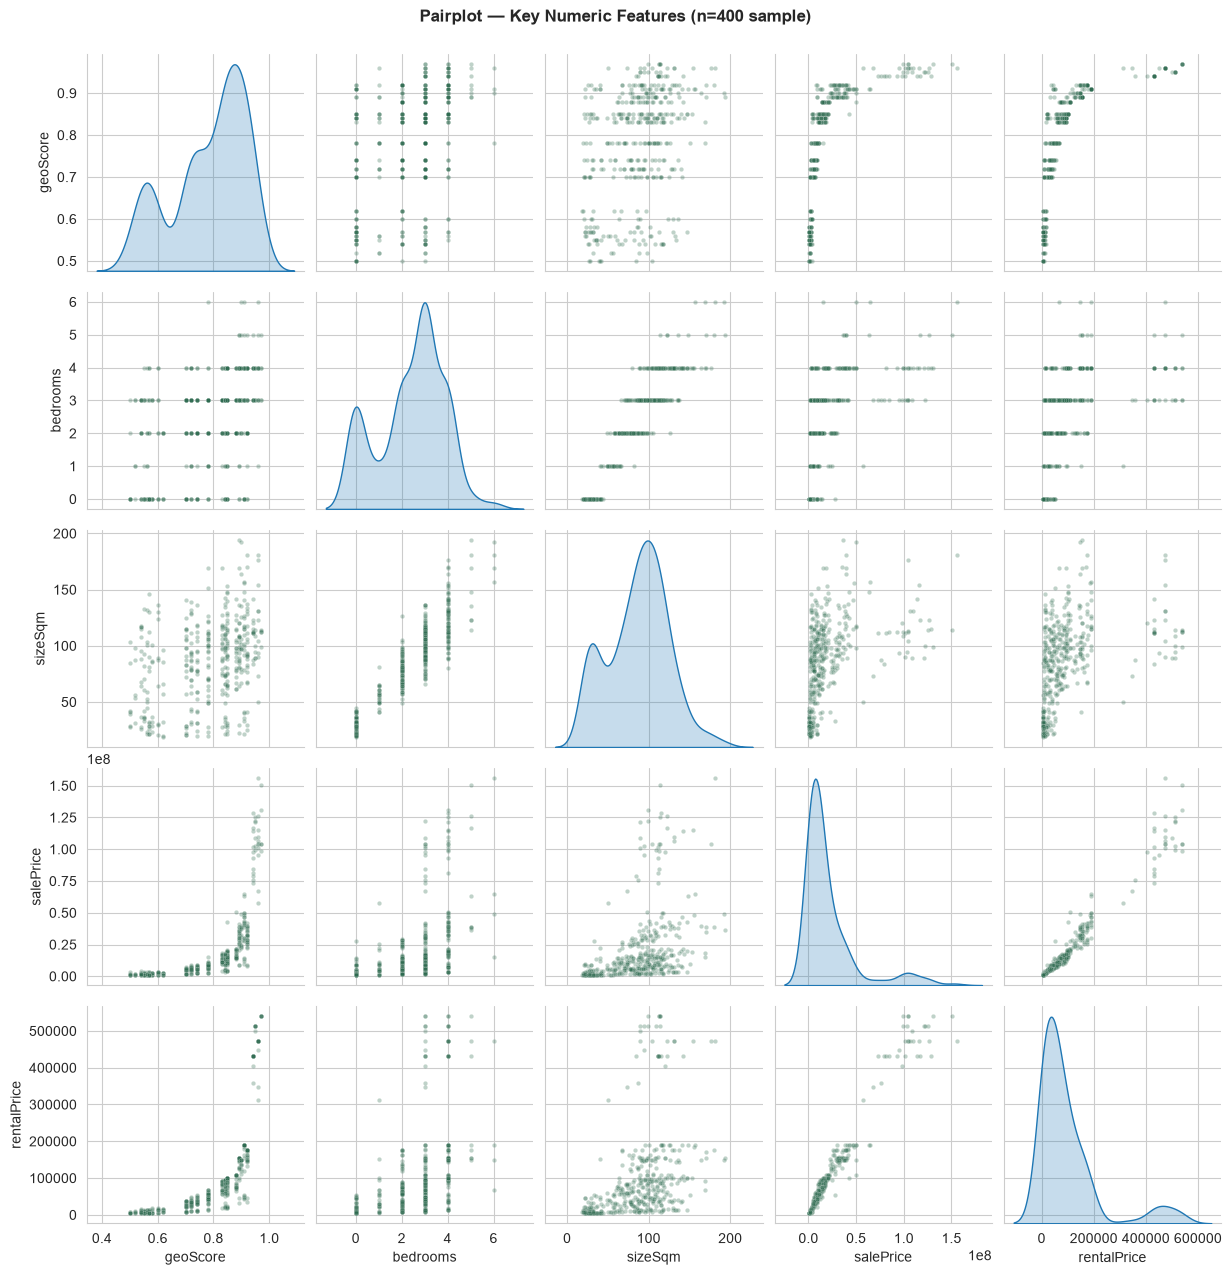

In [19]:
# Pairplot on a 400-row sample for speed
pair_cols = ["geoScore", "bedrooms", "sizeSqm", "salePrice", "rentalPrice"]
sample_df = df_raw[pair_cols].dropna().sample(400, random_state=RANDOM_STATE)

pair_g = sns.pairplot(sample_df, diag_kind="kde",
                      plot_kws={"alpha": 0.3, "s": 10, "color": "#2D6A4F"})
pair_g.fig.suptitle("Pairplot — Key Numeric Features (n=400 sample)",
                    y=1.02, fontsize=12, fontweight="bold")
plt.show()


## 3. Data Cleaning & Preprocessing

**Notes on Modelling Decisions — Data Cleaning**

- **sizeSqm nulls (≈5%):** Imputed with the median per `propertyType` group.
  Group-level median is preferred over global median because size varies
  substantially between Bedsitters (~25 m²) and Villas (~300 m²).

- **hasParking nulls (≈2%):** Imputed with the mode per `location`.
  Parking availability is a neighbourhood-level characteristic
  (e.g. >90% of Runda properties have parking).

- **Outlier removal strategy:** Extreme outliers are removed using a 3× IQR fence
  (more permissive than the default 1.5×) because property prices follow a
  right-skewed distribution and we want to retain legitimate luxury properties
  while removing data entry errors (e.g. a KES 350M apartment in Kasarani).


In [20]:
df = df_raw.copy()

# 3.1 Impute sizeSqm — group median by propertyType
df["sizeSqm"] = df.groupby("propertyType")["sizeSqm"].transform(
    lambda x: x.fillna(x.median()))
print(f"sizeSqm nulls after imputation: {df['sizeSqm'].isnull().sum()}")

# 3.2 Impute hasParking — group mode by location
df["hasParking"] = df.groupby("location")["hasParking"].transform(
    lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else False))
print(f"hasParking nulls after imputation: {df['hasParking'].isnull().sum()}")

# 3.3 Cast boolean columns to int (0/1)
BOOL_COLS = ["hasParking", "hasDSQ", "hasGarden", "hasBorehole", "isFurnished"]
for col in BOOL_COLS:
    df[col] = df[col].astype(int)

print(f"\nAll nulls remaining: {df.isnull().sum().sum()}")


sizeSqm nulls after imputation: 0
hasParking nulls after imputation: 0

All nulls remaining: 0


In [21]:
# 3.4 Remove extreme outliers (3× IQR) from both price targets
def remove_outliers_iqr(dataframe: pd.DataFrame,
                         col: str,
                         factor: float = 3.0) -> pd.DataFrame:
    Q1 = dataframe[col].quantile(0.25)
    Q3 = dataframe[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    before = len(dataframe)
    out = dataframe[(dataframe[col] >= lower) & (dataframe[col] <= upper)].copy()
    print(f"  {col:15s}: removed {before - len(out):3d} rows  "
          f"(kept {lower:>12,.0f} – {upper:>12,.0f})")
    return out

print("Outlier removal (IQR factor = 3.0):")
df = remove_outliers_iqr(df, "salePrice")
df = remove_outliers_iqr(df, "rentalPrice")
df.reset_index(drop=True, inplace=True)
print(f"\nClean dataset: {df.shape}")


Outlier removal (IQR factor = 3.0):
  salePrice      : removed 193 rows  (kept  -68,300,000 –  100,400,000)
  rentalPrice    : removed  61 rows  (kept     -233,250 –      353,000)

Clean dataset: (2446, 13)


## 4. Feature Engineering & Label Encoding

In [22]:
# 4.1 Label-encode categorical features
le_type = LabelEncoder()
le_loc  = LabelEncoder()

df["propertyType_enc"] = le_type.fit_transform(df["propertyType"])
df["location_enc"]     = le_loc.fit_transform(df["location"])

print("propertyType encoding:")
for code_val, cls in enumerate(le_type.classes_):
    print(f"  {code_val} → {cls}")

print("\nlocation encoding sample (first 5):")
for code_val, cls in enumerate(le_loc.classes_[:5]):
    print(f"  {code_val} → {cls}")
print("  ...")


propertyType encoding:
  0 → Apartment
  1 → Bedsitter
  2 → Bungalow
  3 → Maisonette
  4 → Studio
  5 → Townhouse
  6 → Villa

location encoding sample (first 5):
  0 → Buruburu
  1 → Donholm
  2 → Eastleigh
  3 → Embakasi
  4 → Gigiri
  ...


In [23]:
# 4.2 Define candidate feature sets (before selection)
SALE_CANDIDATES = [
    "propertyType_enc", "location_enc", "geoScore",
    "bedrooms", "bathrooms", "sizeSqm",
    "hasParking", "hasDSQ", "hasGarden", "hasBorehole"
]

RENTAL_CANDIDATES = SALE_CANDIDATES + ["isFurnished"]

print(f"Sale candidate features   ({len(SALE_CANDIDATES)}): {SALE_CANDIDATES}")
print(f"Rental candidate features ({len(RENTAL_CANDIDATES)}): {RENTAL_CANDIDATES}")


Sale candidate features   (10): ['propertyType_enc', 'location_enc', 'geoScore', 'bedrooms', 'bathrooms', 'sizeSqm', 'hasParking', 'hasDSQ', 'hasGarden', 'hasBorehole']
Rental candidate features (11): ['propertyType_enc', 'location_enc', 'geoScore', 'bedrooms', 'bathrooms', 'sizeSqm', 'hasParking', 'hasDSQ', 'hasGarden', 'hasBorehole', 'isFurnished']


## 5. Train / Test Split

> **Note:** The split is performed **before** feature selection.
> Feature selection is applied only to training data to prevent data leakage.


**Notes on Modelling Decisions — Train/Test Split**

- **Stratified split on price quantile bins:** Sale and rental prices are right-skewed.
  A plain random split risks all premium-property rows landing in the test set.
  `pd.qcut` creates 5 equal-frequency bins; these are used as strata for `train_test_split`,
  ensuring each price band is proportionally represented in both sets.

- **Split ratio 80/20:** Standard for a 2,600-row dataset; leaves ~520 rows for testing
  while keeping >2,000 rows for feature selection and training.

- **Separate splits for each target:** The two models use slightly different feature sets
  (rental has `isFurnished`), so we create two independent splits from the same index.


In [24]:
# 5.1 Create stratification bins on salePrice
sale_bins = pd.qcut(df["salePrice"], q=5, labels=False, duplicates="drop")

X_sale = df[SALE_CANDIDATES].copy()
y_sale = df["salePrice"].copy()

(X_sale_train, X_sale_test,
 y_sale_train, y_sale_test) = train_test_split(
    X_sale, y_sale,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=sale_bins
)

# 5.2 Same for rentalPrice
rental_bins = pd.qcut(df["rentalPrice"], q=5, labels=False, duplicates="drop")

X_rental = df[RENTAL_CANDIDATES].copy()
y_rental = df["rentalPrice"].copy()

(X_rental_train, X_rental_test,
 y_rental_train, y_rental_test) = train_test_split(
    X_rental, y_rental,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=rental_bins
)

print(f"Sale   — train: {X_sale_train.shape}, test: {X_sale_test.shape}")
print(f"Rental — train: {X_rental_train.shape}, test: {X_rental_test.shape}")


Sale   — train: (1956, 10), test: (490, 10)
Rental — train: (1956, 11), test: (490, 11)


## 6. Feature Selection

Three-stage pipeline applied **on training data only**:

1. **Correlation filtering** — drop one feature from any pair with |r| > 0.8
2. **VIF (Variance Inflation Factor)** — drop features with VIF > 50 to reduce multicollinearity
3. **RFECV** — Recursive Feature Elimination with Cross-Validation using a Random Forest estimator


**Notes on Modelling Decisions — Feature Selection**

- **Correlation threshold 0.8:** Stricter thresholds (e.g. 0.9) risk keeping redundant features;
  looser (e.g. 0.7) may remove genuinely useful predictors. 0.8 is the standard class threshold.

- **VIF threshold 50:** The classic threshold is 10, but our features are mostly binary (0/1)
  which can inflate VIF even when multicollinearity is minimal. A higher threshold (50) prevents
  aggressive removal of legitimately independent binary features.

- **RFECV with Random Forest:** Random Forest handles non-linearity and interactions well and
  is less sensitive to feature scale than linear models. Cross-validation (5-fold) within RFECV
  ensures the selected subset generalises rather than overfitting to one training partition.


In [25]:
def correlation_filter(X: pd.DataFrame,
                       threshold: float = 0.80) -> list:
    """Return list of features to drop due to pairwise correlation > threshold."""
    corr = X.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
    return to_drop


def vif_filter(X: pd.DataFrame, threshold: float = 50.0) -> pd.DataFrame:
    """Iteratively drop the highest-VIF feature until all VIF < threshold."""
    X_vif = X.copy()
    while True:
        vif_data = pd.DataFrame({
            "feature": X_vif.columns,
            "VIF": [variance_inflation_factor(X_vif.values, i)
                    for i in range(X_vif.shape[1])]
        }).sort_values("VIF", ascending=False)

        max_vif = vif_data["VIF"].max()
        if max_vif <= threshold:
            break
        drop_col = vif_data.iloc[0]["feature"]
        print(f"  VIF filter: dropping '{drop_col}' (VIF={max_vif:.1f})")
        X_vif = X_vif.drop(columns=[drop_col])
    return X_vif


def rfecv_filter(X: pd.DataFrame,
                 y: pd.Series,
                 random_state: int = 42) -> list:
    """RFECV with Random Forest; return selected feature names."""
    estimator = RandomForestRegressor(
        n_estimators=50, random_state=random_state, n_jobs=-1)
    selector = RFECV(estimator, step=1, cv=5, scoring="r2", n_jobs=-1)
    selector.fit(X, y)
    selected = X.columns[selector.support_].tolist()
    print(f"  RFECV: kept {len(selected)}/{len(X.columns)} features "
          f"(optimal n={selector.n_features_})")
    return selected


In [26]:
# ── SALE MODEL FEATURE SELECTION ──────────────────────────────
print("\n=== FEATURE SELECTION: salePrice ===")

# Stage 1 — correlation
drop_corr_s = correlation_filter(X_sale_train, threshold=0.80)
print(f"Correlation filter: dropping {drop_corr_s}")
X_sale_tr_s1 = X_sale_train.drop(columns=drop_corr_s)
X_sale_te_s1 = X_sale_test.drop(columns=drop_corr_s)

# Stage 2 — VIF
print("VIF filter:")
X_sale_tr_s2 = vif_filter(X_sale_tr_s1, threshold=50)
dropped_vif_s = [c for c in X_sale_tr_s1.columns
                 if c not in X_sale_tr_s2.columns]
X_sale_te_s2 = X_sale_te_s1.drop(columns=dropped_vif_s, errors="ignore")

# Stage 3 — RFECV
print("RFECV filter:")
sale_features_final = rfecv_filter(X_sale_tr_s2, y_sale_train,
                                    random_state=RANDOM_STATE)

X_sale_train_f = X_sale_tr_s2[sale_features_final]
X_sale_test_f  = X_sale_te_s2[sale_features_final]

print(f"\nFinal sale features ({len(sale_features_final)}): {sale_features_final}")



=== FEATURE SELECTION: salePrice ===
Correlation filter: dropping ['bathrooms', 'sizeSqm']
VIF filter:
RFECV filter:
  RFECV: kept 4/8 features (optimal n=4)

Final sale features (4): ['propertyType_enc', 'location_enc', 'geoScore', 'bedrooms']


In [27]:
# ── RENTAL MODEL FEATURE SELECTION ───────────────────────────
print("\n=== FEATURE SELECTION: rentalPrice ===")

# Stage 1 — correlation
drop_corr_r = correlation_filter(X_rental_train, threshold=0.80)
print(f"Correlation filter: dropping {drop_corr_r}")
X_rental_tr_s1 = X_rental_train.drop(columns=drop_corr_r)
X_rental_te_s1 = X_rental_test.drop(columns=drop_corr_r)

# Stage 2 — VIF
print("VIF filter:")
X_rental_tr_s2 = vif_filter(X_rental_tr_s1, threshold=50)
dropped_vif_r = [c for c in X_rental_tr_s1.columns
                 if c not in X_rental_tr_s2.columns]
X_rental_te_s2 = X_rental_te_s1.drop(columns=dropped_vif_r, errors="ignore")

# Stage 3 — RFECV
print("RFECV filter:")
rental_features_final = rfecv_filter(X_rental_tr_s2, y_rental_train,
                                      random_state=RANDOM_STATE)

X_rental_train_f = X_rental_tr_s2[rental_features_final]
X_rental_test_f  = X_rental_te_s2[rental_features_final]

print(f"\nFinal rental features ({len(rental_features_final)}): {rental_features_final}")



=== FEATURE SELECTION: rentalPrice ===
Correlation filter: dropping ['bathrooms', 'sizeSqm']
VIF filter:
RFECV filter:
  RFECV: kept 9/9 features (optimal n=9)

Final rental features (9): ['propertyType_enc', 'location_enc', 'geoScore', 'bedrooms', 'hasParking', 'hasDSQ', 'hasGarden', 'hasBorehole', 'isFurnished']


## 7. Model Training & Comparison

Five regression algorithms compared for each target.


**Notes on Modelling Decisions — Model Selection**

- **XGBoost:** Gradient-boosted trees with L1/L2 regularisation. Strong baseline for
  structured tabular data; handles the non-linear geoScore × propertyType interaction well.
  `learning_rate=0.08` with `n_estimators=300` trades speed for lower generalisation error.

- **Random Forest:** Ensemble of decision trees; robust to outliers remaining after IQR cleaning.
  `max_depth=12` prevents deep trees from memorising the small premium-property cluster.

- **Gradient Boosting (sklearn):** Slower but often competitive with XGBoost on smaller datasets.
  Included for comparison; expected to be slower to train.

- **Ridge Regression:** Linear baseline. Ridge (L2) is preferred over OLS here because
  `location_enc` and `geoScore` encode the same geographic information and will have
  non-zero correlation, making OLS estimates unstable.

- **SVR (RBF kernel):** Non-linear kernel method. `C` and `epsilon` are chosen to be
  consistent with the KES price scale (~millions for sale, ~thousands for rental).
  SVR does not scale well but serves as a non-tree non-linear baseline.


In [28]:
def evaluate_model(model, X_test, y_test, name="Model") -> dict:
    y_pred = model.predict(X_test)
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / np.maximum(y_test, 1))) * 100
    print(f"  {name:35s} | MAE: {mae:>14,.0f} | RMSE: {rmse:>14,.0f} "
          f"| R²: {r2:.4f} | MAPE: {mape:.1f}%")
    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape}


In [29]:
# ── SALE PRICE MODELS ─────────────────────────────────────────
SALE_MODELS = {
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.08, max_depth=6,
        subsample=0.85, colsample_bytree=0.85,
        random_state=RANDOM_STATE, verbosity=0
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=12,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.10,
        max_depth=5, random_state=RANDOM_STATE
    ),
    "Ridge Regression": Ridge(alpha=1.0),
    "SVR": SVR(kernel="rbf", C=1e6, epsilon=5e4),
}

print("=== SALE PRICE — MODEL COMPARISON ===")
print(f"  {'Model':35s} | {'MAE':>14s} | {'RMSE':>14s} | {'R²':>6s} | MAPE")
print("  " + "─" * 90)

sale_results, trained_sale = [], {}
for name, model in SALE_MODELS.items():
    model.fit(X_sale_train_f, y_sale_train)
    res = evaluate_model(model, X_sale_test_f, y_sale_test, name)
    sale_results.append(res)
    trained_sale[name] = model

sale_perf = pd.DataFrame(sale_results).sort_values("R2", ascending=False)
print(f"\n  ★ Best model: {sale_perf.iloc[0]['model']}")


=== SALE PRICE — MODEL COMPARISON ===
  Model                               |            MAE |           RMSE |     R² | MAPE
  ──────────────────────────────────────────────────────────────────────────────────────────
  XGBoost                             | MAE:      1,418,792 | RMSE:      4,211,460 | R²: 0.9054 | MAPE: 9.5%
  Random Forest                       | MAE:      1,414,833 | RMSE:      4,187,701 | R²: 0.9065 | MAPE: 9.0%
  Gradient Boosting                   | MAE:      1,411,535 | RMSE:      4,205,921 | R²: 0.9057 | MAPE: 9.0%
  Ridge Regression                    | MAE:      6,182,516 | RMSE:      8,150,991 | R²: 0.6458 | MAPE: 127.3%
  SVR                                 | MAE:      6,351,958 | RMSE:     10,053,287 | R²: 0.4611 | MAPE: 82.2%

  ★ Best model: Random Forest


In [30]:
# ── RENTAL PRICE MODELS ───────────────────────────────────────
RENTAL_MODELS = {
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.08, max_depth=6,
        subsample=0.85, colsample_bytree=0.85,
        random_state=RANDOM_STATE, verbosity=0
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=12,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.10,
        max_depth=5, random_state=RANDOM_STATE
    ),
    "Ridge Regression": Ridge(alpha=1.0),
    "SVR": SVR(kernel="rbf", C=1e5, epsilon=1000),
}

print("=== RENTAL PRICE — MODEL COMPARISON ===")
print(f"  {'Model':35s} | {'MAE':>14s} | {'RMSE':>14s} | {'R²':>6s} | MAPE")
print("  " + "─" * 90)

rental_results, trained_rental = [], {}
for name, model in RENTAL_MODELS.items():
    model.fit(X_rental_train_f, y_rental_train)
    res = evaluate_model(model, X_rental_test_f, y_rental_test, name)
    rental_results.append(res)
    trained_rental[name] = model

rental_perf = pd.DataFrame(rental_results).sort_values("R2", ascending=False)
print(f"\n  ★ Best model: {rental_perf.iloc[0]['model']}")


=== RENTAL PRICE — MODEL COMPARISON ===
  Model                               |            MAE |           RMSE |     R² | MAPE
  ──────────────────────────────────────────────────────────────────────────────────────────
  XGBoost                             | MAE:          2,648 | RMSE:          4,199 | R²: 0.9944 | MAPE: 5.3%
  Random Forest                       | MAE:          2,707 | RMSE:          4,527 | R²: 0.9935 | MAPE: 5.0%
  Gradient Boosting                   | MAE:          2,700 | RMSE:          4,233 | R²: 0.9943 | MAPE: 5.1%
  Ridge Regression                    | MAE:         21,079 | RMSE:         27,441 | R²: 0.7622 | MAPE: 88.4%
  SVR                                 | MAE:         19,264 | RMSE:         31,572 | R²: 0.6853 | MAPE: 50.7%

  ★ Best model: XGBoost


## 8. Model Evaluation

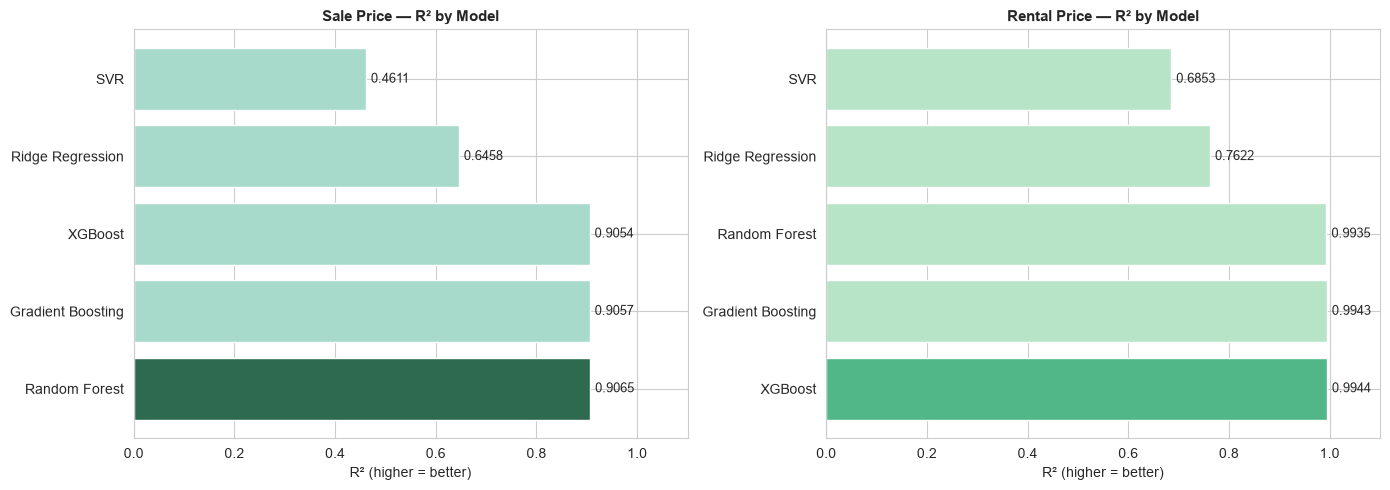

In [31]:
# 8.1 R² comparison chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, perf, label, color_best, color_rest in [
    (axes[0], sale_perf,   "Sale Price",   "#2D6A4F", "#A8DACC"),
    (axes[1], rental_perf, "Rental Price", "#52B788", "#B7E4C7"),
]:
    colors = [color_best if i == 0 else color_rest
              for i in range(len(perf))]
    ax.barh(perf["model"], perf["R2"], color=colors, edgecolor="white")
    ax.set_xlim(0, 1.10)
    ax.set_title(f"{label} — R² by Model", fontsize=11, fontweight="bold")
    ax.set_xlabel("R² (higher = better)")
    for i, v in enumerate(perf["R2"]):
        ax.text(v + 0.01, i, f"{v:.4f}", va="center", fontsize=9)

plt.tight_layout()
plt.show()


In [32]:
# 8.2 Select best models
best_sale_name   = sale_perf.iloc[0]["model"]
best_rental_name = rental_perf.iloc[0]["model"]
best_sale_mdl    = trained_sale[best_sale_name]
best_rental_mdl  = trained_rental[best_rental_name]

print(f"Selected sale model:   {best_sale_name}")
print(f"Selected rental model: {best_rental_name}")


Selected sale model:   Random Forest
Selected rental model: XGBoost


In [33]:
# 8.3 5-fold cross-validation on best models
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_sale = cross_val_score(
    best_sale_mdl, X_sale_train_f, y_sale_train,
    cv=kf, scoring="r2", n_jobs=-1)

cv_rental = cross_val_score(
    best_rental_mdl, X_rental_train_f, y_rental_train,
    cv=kf, scoring="r2", n_jobs=-1)

print(f"CV — {best_sale_name} (Sale):")
print(f"  Folds: {cv_sale.round(4)}")
print(f"  Mean:  {cv_sale.mean():.4f}  ±  {cv_sale.std():.4f}")

print(f"\nCV — {best_rental_name} (Rental):")
print(f"  Folds: {cv_rental.round(4)}")
print(f"  Mean:  {cv_rental.mean():.4f}  ±  {cv_rental.std():.4f}")


CV — Random Forest (Sale):
  Folds: [0.9592 0.9639 0.9531 0.9256 0.9484]
  Mean:  0.9500  ±  0.0133

CV — XGBoost (Rental):
  Folds: [0.9952 0.9914 0.9867 0.99   0.993 ]
  Mean:  0.9912  ±  0.0029


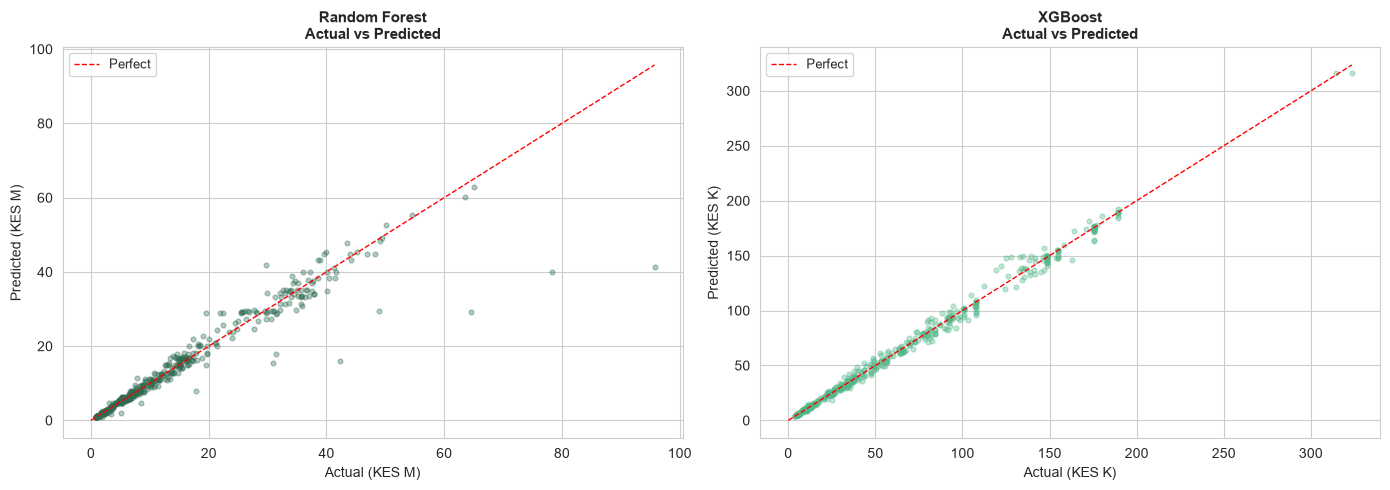

In [34]:
# 8.4 Actual vs Predicted scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y_sale_pred   = best_sale_mdl.predict(X_sale_test_f)
y_rental_pred = best_rental_mdl.predict(X_rental_test_f)

for ax, y_true, y_pred, label, color, scale, unit in [
    (axes[0], y_sale_test, y_sale_pred, best_sale_name, "#2D6A4F", 1e6, "M"),
    (axes[1], y_rental_test, y_rental_pred, best_rental_name, "#52B788", 1e3, "K"),
]:
    ax.scatter(y_true / scale, y_pred / scale,
               alpha=0.35, s=12, color=color)
    lim = max(y_true.max(), y_pred.max()) / scale
    ax.plot([0, lim], [0, lim], "r--", lw=1, label="Perfect")
    ax.set_xlabel(f"Actual (KES {unit})", fontsize=10)
    ax.set_ylabel(f"Predicted (KES {unit})", fontsize=10)
    ax.set_title(f"{label}\nActual vs Predicted", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


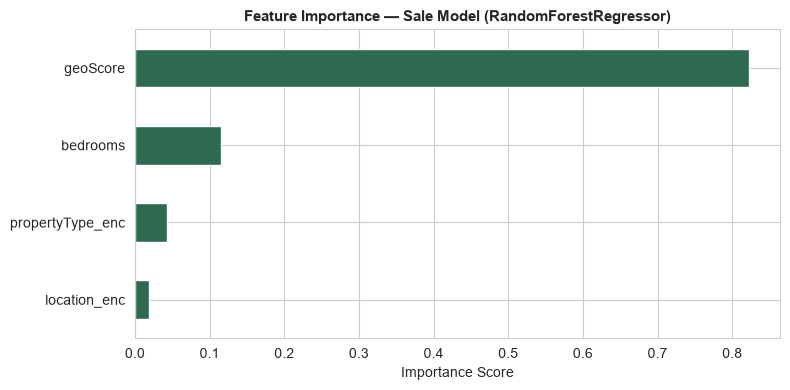

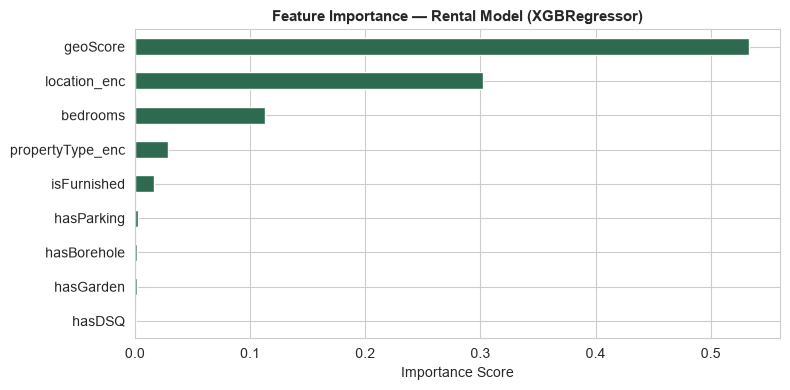

In [35]:
# 8.5 Feature importance (tree-based models only)
for label, model, features in [
    ("Sale",   best_sale_mdl,   sale_features_final),
    ("Rental", best_rental_mdl, rental_features_final),
]:
    if not hasattr(model, "feature_importances_"):
        print(f"{label}: {type(model).__name__} has no feature importances (skipping)")
        continue

    imp = (pd.Series(model.feature_importances_, index=features)
             .sort_values(ascending=True))

    fig, ax = plt.subplots(figsize=(8, 4))
    imp.plot(kind="barh", ax=ax, color="#2D6A4F", edgecolor="white")
    ax.set_title(f"Feature Importance — {label} Model ({type(model).__name__})",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Importance Score")
    plt.tight_layout()
    plt.show()


## 9. Save Final Models

Re-train on the full dataset (train + test combined) before saving.


In [36]:
# 9.1 Combine train + test for final fit
X_sale_full   = pd.concat([X_sale_train_f,   X_sale_test_f])
y_sale_full   = pd.concat([y_sale_train,      y_sale_test])

X_rental_full = pd.concat([X_rental_train_f, X_rental_test_f])
y_rental_full = pd.concat([y_rental_train,   y_rental_test])

# Re-create model instances with the same hyperparameters
final_sale   = type(best_sale_mdl)(**best_sale_mdl.get_params())
final_rental = type(best_rental_mdl)(**best_rental_mdl.get_params())

print("Re-training on full dataset...")
final_sale.fit(X_sale_full, y_sale_full)
final_rental.fit(X_rental_full, y_rental_full)
print("Done.")


Re-training on full dataset...
Done.


In [37]:
# 9.2 Save all 4 joblib files
# DEV: save straight into the project's models/ folder, which the backend reads
MODELS_DIR = "models" if ENVIRONMENT == "COLAB" else "../models"
os.makedirs(MODELS_DIR, exist_ok=True)

joblib.dump(final_sale,   f"{MODELS_DIR}/sale_model.joblib")
joblib.dump(final_rental, f"{MODELS_DIR}/rental_model.joblib")
joblib.dump(le_type,      f"{MODELS_DIR}/encoder_propertyType.joblib")
joblib.dump(le_loc,       f"{MODELS_DIR}/encoder_location.joblib")

# Also save the selected feature lists so the API knows which columns to pass
import json as _json
with open(f"{MODELS_DIR}/sale_features.json", "w") as f:
    _json.dump(sale_features_final, f)
with open(f"{MODELS_DIR}/rental_features.json", "w") as f:
    _json.dump(rental_features_final, f)

print(f"Saved to {MODELS_DIR}/:")
for fname in os.listdir(MODELS_DIR):
    size = os.path.getsize(f"{MODELS_DIR}/{fname}")
    print(f"  {fname:40s} {size/1024:>8.1f} KB")


Saved to ../models/:
  encoder_location.joblib                       0.9 KB
  encoder_propertyType.joblib                   0.6 KB
  rental_features.json                          0.1 KB
  rental_model.joblib                        1229.0 KB
  sale_features.json                            0.1 KB
  sale_model.joblib                          7655.5 KB


In [38]:
# 9.3 Download to local machine (Colab only)
if ENVIRONMENT == "COLAB":
    from google.colab import files
    for fname in [
        f"{MODELS_DIR}/sale_model.joblib",
        f"{MODELS_DIR}/rental_model.joblib",
        f"{MODELS_DIR}/encoder_propertyType.joblib",
        f"{MODELS_DIR}/encoder_location.joblib",
        f"{MODELS_DIR}/sale_features.json",
        f"{MODELS_DIR}/rental_features.json",
    ]:
        files.download(fname)
        print(f"↓ {fname}")
    print("\nPlace all files in  nyumbaai/models/  on your machine.")
else:
    print(f"DEV mode — files saved to {MODELS_DIR}/")


DEV mode — files saved to ../models/


## 10. Prediction Function

This function mirrors `backend/services/prediction_service.py` exactly.
Test it here before wiring into FastAPI.


In [39]:
# 10.1 Reload saved models (simulates FastAPI startup)
final_sale_loaded   = joblib.load(f"{MODELS_DIR}/sale_model.joblib")
final_rental_loaded = joblib.load(f"{MODELS_DIR}/rental_model.joblib")
le_type_loaded      = joblib.load(f"{MODELS_DIR}/encoder_propertyType.joblib")
le_loc_loaded       = joblib.load(f"{MODELS_DIR}/encoder_location.joblib")

with open(f"{MODELS_DIR}/sale_features.json")   as f: SALE_FEATS   = _json.load(f)
with open(f"{MODELS_DIR}/rental_features.json") as f: RENTAL_FEATS = _json.load(f)

print("Models reloaded.")
print(f"  Sale model:   {type(final_sale_loaded).__name__}")
print(f"  Rental model: {type(final_rental_loaded).__name__}")
print(f"  Sale features ({len(SALE_FEATS)}): {SALE_FEATS}")
print(f"  Rental features ({len(RENTAL_FEATS)}): {RENTAL_FEATS}")


Models reloaded.
  Sale model:   RandomForestRegressor
  Rental model: XGBRegressor
  Sale features (4): ['propertyType_enc', 'location_enc', 'geoScore', 'bedrooms']
  Rental features (9): ['propertyType_enc', 'location_enc', 'geoScore', 'bedrooms', 'hasParking', 'hasDSQ', 'hasGarden', 'hasBorehole', 'isFurnished']


In [40]:
# 10.2 GeoScore lookup (must match backend/services/prediction_service.py)
GEO_SCORES = {
    "Runda": 0.97, "Karen": 0.96, "Gigiri": 0.94, "Muthaiga": 0.95,
    "Kilimani": 0.92, "Kitisuru": 0.91, "Westlands": 0.90, "Lavington": 0.89,
    "Kileleshwa": 0.88, "Parklands": 0.85, "Hurlingham": 0.84, "Upper Hill": 0.83,
    "Ngong Road": 0.78, "Langata": 0.74, "South B": 0.72, "South C": 0.70,
    "Rongai": 0.62, "Ruaka": 0.60, "Kasarani": 0.58, "Thika Road": 0.57,
    "Donholm": 0.56, "Embakasi": 0.55, "Umoja": 0.52, "Buruburu": 0.54,
    "Eastleigh": 0.50,
}

def predict_prices(
    property_type: str,
    location: str,
    bedrooms: int,
    bathrooms: int,
    size_sqm: float,
    has_parking: bool,
    has_dsq: bool,
    has_garden: bool,
    has_borehole: bool,
    is_furnished: bool = False,
) -> dict:
    """
    Returns predicted sale and rental prices in KES.
    Mirrors backend/services/prediction_service.py

    Parameters
    ----------
    property_type : one of Apartment | Maisonette | Bungalow |
                    Townhouse | Villa | Bedsitter | Studio
    location      : one of the 25 supported Nairobi neighbourhoods
    ...

    Returns
    -------
    dict with predicted_sale_price, predicted_rental_price,
         location, geo_score
    """
    geo_score = GEO_SCORES.get(location, 0.60)

    try:
        pt_enc  = int(le_type_loaded.transform([property_type])[0])
        loc_enc = int(le_loc_loaded.transform([location])[0])
    except ValueError as exc:
        raise ValueError(f"Unsupported category value: {exc}") from exc

    all_features = {
        "propertyType_enc": pt_enc,
        "location_enc":     loc_enc,
        "geoScore":         geo_score,
        "bedrooms":         bedrooms,
        "bathrooms":        bathrooms,
        "sizeSqm":          size_sqm,
        "hasParking":       int(has_parking),
        "hasDSQ":           int(has_dsq),
        "hasGarden":        int(has_garden),
        "hasBorehole":      int(has_borehole),
        "isFurnished":      int(is_furnished),
    }

    X_sale_input   = pd.DataFrame([[all_features[f] for f in SALE_FEATS]],
                                   columns=SALE_FEATS)
    X_rental_input = pd.DataFrame([[all_features[f] for f in RENTAL_FEATS]],
                                   columns=RENTAL_FEATS)

    raw_sale   = float(final_sale_loaded.predict(X_sale_input)[0])
    raw_rental = float(final_rental_loaded.predict(X_rental_input)[0])

    sale_price   = int(round(max(raw_sale,   0) / 50_000) * 50_000)
    rental_price = int(round(max(raw_rental, 0) / 500)    * 500)

    return {
        "predicted_sale_price":   sale_price,
        "predicted_rental_price": rental_price,
        "location":               location,
        "geo_score":              geo_score,
    }

print("predict_prices() ready.")


predict_prices() ready.


In [41]:
# 10.3 Test predictions
TEST_CASES = [
    dict(property_type="Apartment",  location="Kilimani",  bedrooms=2,
         bathrooms=2, size_sqm=85,  has_parking=True,  has_dsq=False,
         has_garden=False, has_borehole=False, is_furnished=True),

    dict(property_type="Maisonette", location="Karen",     bedrooms=4,
         bathrooms=3, size_sqm=220, has_parking=True,  has_dsq=True,
         has_garden=True,  has_borehole=True,  is_furnished=False),

    dict(property_type="Bedsitter",  location="Kasarani",  bedrooms=0,
         bathrooms=1, size_sqm=25,  has_parking=False, has_dsq=False,
         has_garden=False, has_borehole=False, is_furnished=True),

    dict(property_type="Bungalow",   location="Langata",   bedrooms=3,
         bathrooms=2, size_sqm=140, has_parking=True,  has_dsq=False,
         has_garden=True,  has_borehole=False, is_furnished=False),

    dict(property_type="Villa",      location="Runda",     bedrooms=5,
         bathrooms=5, size_sqm=380, has_parking=True,  has_dsq=True,
         has_garden=True,  has_borehole=True,  is_furnished=False),
]

print(f"{'Type':<12} {'Location':<12} {'Bd':>2} {'Sz':>5}  "
      f"{'Sale Price (KES)':>18}  {'Rental/mo (KES)':>18}")
print("─" * 75)
for tc in TEST_CASES:
    r = predict_prices(**tc)
    print(f"{tc['property_type']:<12} {tc['location']:<12} "
          f"{tc['bedrooms']:>2} {tc['size_sqm']:>4.0f}m²  "
          f"{r['predicted_sale_price']:>18,}  "
          f"{r['predicted_rental_price']:>18,}")


Type         Location     Bd    Sz    Sale Price (KES)     Rental/mo (KES)
───────────────────────────────────────────────────────────────────────────
Apartment    Kilimani      2   85m²          26,800,000             172,500
Maisonette   Karen         4  220m²          59,500,000             290,000
Bedsitter    Kasarani      0   25m²           1,200,000               5,500
Bungalow     Langata       3  140m²           7,250,000              37,500
Villa        Runda         5  380m²          61,650,000             217,500
